# Livrable 1 — Modélisation des tournées de livraison (CVRP → CVRPTW)

**CesiCDP — Appel à manifestation d'intérêt ADEME**

1. Contexte
2. Du terrain au modèle
3. Données et définition du problème
4. Complexité
5. PLNE du CVRP
6. Extension aux fenêtres de temps (CVRPTW)
7. Et le trafic ?
8. Illustration
9. Synthèse
10. Références

## 1. Contexte

L'ADEME cherche des solutions pour réduire l'impact du transport de marchandises. Chaque kilomètre ou minute de route en moins, c'est du carburant et du CO₂ en moins.

CesiCDP s'intéresse aux **tournées de livraison** : un dépôt, une flotte de camions, une liste de clients à livrer.

> **Question :** quel camion livre quel client, et dans quel ordre, pour que la durée totale des tournées soit minimale ?

Le sujet propose deux niveaux. Nous visons le **niveau A**, en construisant d'abord le niveau B, qui en est le socle.

| Niveau | Problème | Contraintes |
|---|---|---|
| B | **CVRP** | $K$ camions identiques de capacité $Q$ |
| A | **CVRPTW** | CVRP + une fenêtre horaire stricte par client, attente autorisée |

## 2. Du terrain au modèle

| Terrain | Modèle |
|---|---|
| Dépôt, clients | sommets d'un graphe |
| Trajet entre deux lieux | arc de durée $t_{ij}$ |
| Commande d'un client | demande $q_i$ |
| Volume d'un camion | capacité $Q$ |
| Nombre de camions | $K$ |
| Créneau de livraison | fenêtre $[a_i, b_i]$ |
| Temps de déchargement | temps de service $s_i$ |
| Tournée d'un camion | circuit qui part du dépôt et y revient |

**Hypothèses**

- **H1 — Graphe complet.** On ne garde que le dépôt et les clients. $t_{ij}$ est la durée du plus court chemin routier de $i$ à $j$ (pré-calculée, par exemple avec Dijkstra). Conséquence : l'inégalité triangulaire $t_{ij} \le t_{ik} + t_{kj}$ est respectée.
- **H2 — Pas de livraison fractionnée.** Un client est livré par un seul camion, en une seule fois.
- **H3 — Flotte homogène.** Tous les camions ont la capacité $Q$ et partent du même dépôt.
- **H4 — $q_i \le Q$** pour tout client (sinon l'instance est impossible).
- **H5 — Durées fixes.** Le trafic variable est discuté à part (section 7).

## 3. Données et définition du problème

### 3.1 Les données

- $V = \{0, 1, \dots, n\}$ : le sommet $0$ est le **dépôt**, $V^* = \{1, \dots, n\}$ sont les **clients**.
- $A = \{(i,j) : i \neq j\}$ : tous les arcs (graphe complet, orienté car $t_{ij}$ peut différer de $t_{ji}$).
- $t_{ij} \ge 0$ : durée de trajet de $i$ à $j$.
- $q_i$ : demande du client $i$ ($q_0 = 0$).
- $Q$ : capacité d'un camion, $K$ : nombre de camions.
- *(CVRPTW)* $[a_i, b_i]$ : fenêtre de début de service de $i$. Pour le dépôt, $[a_0, b_0]$ = heures d'ouverture.
- *(CVRPTW)* $s_i$ : temps de service ($s_0 = 0$).

### 3.2 Une solution

Une solution est un ensemble de **routes** (au plus $K$). Une route est une suite $(0, v_1, v_2, \dots, v_\ell, 0)$.

Son **coût** est la somme des durées des arcs parcourus. **Objectif : minimiser le coût total de toutes les routes.**

### 3.3 Quand une solution est-elle valide ?

**CVRP** :
1. **Couverture** : chaque client est dans exactement une route.
2. **Capacité** : la somme des demandes d'une route est $\le Q$.
3. **Flotte** : au plus $K$ routes.

**CVRPTW**, en plus :

4. **Fenêtres** : le service de chaque client commence dans $[a_i, b_i]$, et le camion rentre au dépôt avant $b_0$.

L'heure de début de service $T$ se calcule de proche en proche le long de la route :

$$
T_{\text{suivant}} = \max\big(\;a_{\text{suivant}},\;\; T_{\text{actuel}} + s_{\text{actuel}} + t_{\text{actuel} \to \text{suivant}}\;\big)
$$

Le $\max$ traduit la règle du sujet : **si le camion arrive trop tôt, il attend**. S'il arrive après $b_i$, la solution est **invalide**.

### 3.4 Lien avec la littérature

Ce problème est le **Vehicle Routing Problem** (Dantzig et Ramser, 1959). Chaque version généralise la précédente :

```
TSP  ──(+ plusieurs camions, capacité)──►  CVRP  ──(+ fenêtres)──►  CVRPTW  ──(+ trafic)──►  TD-CVRPTW
```

**Choix de l'objectif.** On minimise la **somme des temps de trajet**. C'est le critère des instances de référence (VRPLIB, Solomon), donc celui qui permettra de calculer le gap. Il est aussi cohérent avec l'enjeu environnemental : c'est le temps passé à rouler qui émet du CO₂, pas l'attente moteur coupé.

## 4. Complexité

**But :** montrer que le CVRP et le CVRPTW sont **NP-difficiles**. Sauf si P = NP, aucun algorithme ne les résout exactement en temps polynomial.

**Méthode** pour montrer qu'un problème est NP-complet :
1. il est dans **NP** (une solution se vérifie en temps polynomial) ;
2. un problème **déjà connu** NP-complet se **réduit** à lui.

> ⚠️ **Le sens compte.** On transforme le problème connu (TSP) **en** notre problème (CVRP). Le raisonnement : « si je savais résoudre le CVRP vite, je saurais résoudre le TSP vite, or c'est réputé impossible ».

On travaille sur la **version décisionnelle** : *existe-t-il une solution valide de coût $\le B$ ?*

### 4.1 Le CVRP est dans NP

On reçoit une liste de routes. On vérifie en $O(n)$ :
- chaque client présent une fois (tableau de marquage) ;
- la charge de chaque route $\le Q$ ;
- au plus $K$ routes ;
- coût total $\le B$.

Pour le CVRPTW, on calcule en plus les heures $T$ avec la formule de la section 3.3 : toujours $O(n)$.

### 4.2 Réduction TSP → CVRP

**TSP (décision)** : existe-t-il un circuit passant une fois par chaque sommet, de coût $\le B$ ? Ce problème est NP-complet (Karp, 1972 ; Garey et Johnson, 1979).

**Transformation** d'une instance TSP en instance CVRP :

| CVRP | Valeur |
|---|---|
| Dépôt | le sommet 0 du TSP |
| Clients | les autres sommets |
| $t_{ij}$ | $= c_{ij}$ (les coûts du TSP) |
| $q_i$ | $= 1$ |
| $Q$ | $= n$ (la capacité ne bloque jamais) |
| $K$ | $= 1$ (un seul camion) |
| $B$ | inchangé |

C'est une simple recopie : $O(n^2)$, donc **polynomiale**.

**Les deux réponses sont identiques :**
- **TSP oui ⇒ CVRP oui.** Le circuit du TSP, lu à partir de 0, est une route qui visite tous les clients, de charge $n = Q$, avec 1 camion et un coût $\le B$.
- **CVRP oui ⇒ TSP oui.** Avec $K = 1$, la solution est une seule route qui passe une fois par chaque client : c'est un circuit hamiltonien de coût $\le B$.

✅ **Le CVRP est NP-complet** (version décision), donc **NP-difficile** (version optimisation).

### 4.3 Réduction CVRP → CVRPTW

On prend une instance CVRP et on ajoute des fenêtres qui ne gênent jamais : $a_i = 0$, $s_i = 0$, $b_i = $ somme de toutes les durées (plus long que n'importe quelle route). Les solutions valides sont exactement les mêmes.

✅ **Le CVRPTW est NP-difficile.**

### 4.4 Deux remarques importantes

- **Deux difficultés cumulées.** Le CVRP mélange un problème d'**affectation** (quels clients dans quel camion, c'est le *bin packing*, NP-complet) et un problème d'**ordre** (dans quel ordre les visiter, c'est le TSP).
- **Avec fenêtres de temps, même trouver une solution valide est difficile.** Avec un nombre de camions fixé, décider s'il existe une solution réalisable est déjà NP-complet (Savelsbergh, 1985).

### 4.5 Ordre de grandeur

Pour une seule route de $n$ clients, il y a $n!$ ordres de visite possibles :

In [1]:
import math

for n in (10, 20, 50, 100, 1000):
    print(f"n = {n:>4} clients  ->  n! ≈ 10^{math.lgamma(n + 1) / math.log(10):.0f}")

n =   10 clients  ->  n! ≈ 10^7
n =   20 clients  ->  n! ≈ 10^18
n =   50 clients  ->  n! ≈ 10^64
n =  100 clients  ->  n! ≈ 10^158
n = 1000 clients  ->  n! ≈ 10^2568


Tout énumérer est impossible bien avant les « plusieurs milliers de villes » du cahier des charges.

## 5. PLNE du CVRP

### 5.1 Variables

| Variable | Type | Sens |
|---|---|---|
| $x_{ij}$ | binaire | 1 si un camion va directement de $i$ à $j$ |
| $u_i$ | réelle | charge transportée par le camion après avoir livré $i$ (cumul) |

**Pourquoi pas $x_{ijk}$ avec un indice camion ?** Les camions sont identiques. Numéroter les camions multiplie les variables par $K$ et crée des solutions équivalentes (échanger deux camions), qui ralentissent un solveur.

### 5.2 Objectif

$$
\min \sum_{(i,j) \in A} t_{ij}\, x_{ij} \tag{1}
$$

### 5.3 Contraintes

**Chaque client a exactement un arc entrant et un arc sortant** (il est visité une fois) :

$$
\sum_{i \neq j} x_{ij} = 1 \quad \forall j \in V^* \tag{2}
$$
$$
\sum_{j \neq i} x_{ij} = 1 \quad \forall i \in V^* \tag{3}
$$

**Au plus $K$ camions partent du dépôt, et autant y reviennent :**

$$
\sum_{j \in V^*} x_{0j} \le K \tag{4}
$$
$$
\sum_{j \in V^*} x_{0j} = \sum_{i \in V^*} x_{i0} \tag{5}
$$

**Capacité et suppression des sous-tours** (contraintes MTZ, Miller, Tucker et Zemlin, 1960) :

$$
u_j \ge u_i + q_j - Q(1 - x_{ij}) \quad \forall i \ne j \in V^* \tag{6}
$$
$$
q_i \le u_i \le Q \quad \forall i \in V^* \tag{7}
$$

$$
x_{ij} \in \{0, 1\} \tag{8}
$$

### 5.4 Comprendre (6) et (7)

**Le problème à éviter : les sous-tours.** Avec (2) et (3) seules, la solution « $1 \to 2 \to 3 \to 1$ » est acceptée : chaque client a bien une entrée et une sortie, mais ce circuit ne passe pas par le dépôt. Aucun camion ne peut le faire.

**La contrainte (6) est un interrupteur :**
- **$x_{ij} = 1$** (on va de $i$ à $j$) : elle devient $u_j \ge u_i + q_j$. La charge augmente de la demande de $j$.
- **$x_{ij} = 0$** : elle devient $u_j \ge u_i + q_j - Q$. Comme $u_i \le Q$, le membre de droite est $\le q_j \le u_j$ : la contrainte est **toujours vraie**, elle ne sert à rien.

**Pourquoi les sous-tours disparaissent :** sur un sous-tour $1 \to 2 \to 3 \to 1$, la charge devrait augmenter à chaque étape : $u_1 < u_2 < u_3 < u_1$. C'est impossible. Seul le dépôt, qui n'a pas de $u$, permet de « remettre la charge à zéro ».

**Pourquoi la capacité est respectée :** la charge augmente le long de la route et (7) l'empêche de dépasser $Q$.

### 5.5 Taille du modèle

Environ $n^2$ variables binaires et $n^2$ contraintes. Le modèle est **compact**, donc facile à écrire dans un solveur.

Son point faible : sa relaxation linéaire (le même problème avec des $x$ réels) est **faible**. Une alternative plus forte remplace (6)–(7) par les **contraintes de capacité arrondies** (Laporte et Nobert, 1983) :

$$
\sum_{i \notin S} \sum_{j \in S} x_{ij} \ge \left\lceil \frac{\sum_{i \in S} q_i}{Q} \right\rceil \quad \forall S \subseteq V^*
$$

En clair : *un groupe de clients $S$ doit recevoir au moins autant de camions qu'il en faut pour transporter sa demande.* Elles sont plus fortes, mais il y en a $2^n$. On garde MTZ pour sa simplicité.

## 6. Extension aux fenêtres de temps (CVRPTW)

On garde **tout** le modèle (1)–(8) et on ajoute le temps.

### 6.1 Nouvelle variable

| Variable | Type | Sens |
|---|---|---|
| $T_i$ | réelle | heure de **début de service** chez le client $i$ |

### 6.2 Nouvelles contraintes

**Enchaînement de deux clients** : on ne commence pas chez $j$ avant d'avoir fini chez $i$ et roulé jusqu'à $j$.

$$
T_j \ge T_i + s_i + t_{ij} - M_{ij}(1 - x_{ij}) \quad \forall i \ne j \in V^* \tag{9}
$$

**Départ du dépôt** : le premier client ne peut être servi avant l'ouverture du dépôt plus le trajet.

$$
T_j \ge a_0 + t_{0j}\, x_{0j} \quad \forall j \in V^* \tag{10}
$$

**Retour au dépôt avant sa fermeture :**

$$
T_i + s_i + t_{i0} \le b_0 + M_{i0}(1 - x_{i0}) \quad \forall i \in V^* \tag{11}
$$

**Respect des fenêtres :**

$$
a_i \le T_i \le b_i \quad \forall i \in V^* \tag{12}
$$

### 6.3 Comprendre ces contraintes

- **(9) est un interrupteur**, comme (6) : active si $x_{ij} = 1$, neutralisée par le grand nombre $M_{ij}$ si $x_{ij} = 0$.
- **L'attente est autorisée** parce que (9) est un « $\ge$ » et pas un « $=$ ». Si le camion arrive avant $a_j$, (12) pousse simplement $T_j$ jusqu'à $a_j$ : le camion attend. C'est l'équivalent du $\max$ de la section 3.3.
- **Livrer en retard est interdit** grâce à $T_i \le b_i$ dans (12).

### 6.4 Bien choisir les « big-M »

Un $M$ énorme (par exemple $10^9$) affaiblit le modèle et cause des erreurs numériques. On prend **le plus petit $M$ qui neutralise la contrainte**, en se plaçant dans le pire cas (partir de $i$ au plus tard, arriver chez $j$ au plus tôt) :

$$
M_{ij} = \max(0,\; b_i + s_i + t_{ij} - a_j) \qquad M_{i0} = \max(0,\; b_i + s_i + t_{i0} - b_0)
$$

### 6.5 Supprimer d'avance les arcs impossibles

Certains arcs ne pourront jamais être utilisés. On fixe $x_{ij} = 0$ avant toute résolution si :
- **temps** : $a_i + s_i + t_{ij} > b_j$ (même en partant au plus tôt de $i$, on arrive trop tard chez $j$) ;
- **capacité** : $q_i + q_j > Q$ (les deux clients ne tiennent pas dans un même camion).

Le modèle devient plus petit, sans rien changer à ses solutions.

### 6.6 Récapitulatif du modèle CVRPTW

$$
\begin{aligned}
\min \quad & \sum_{(i,j) \in A} t_{ij}\, x_{ij} \\[4pt]
\text{s.c.} \quad
& \textstyle\sum_{i \neq j} x_{ij} = 1, \;\; \sum_{i \neq j} x_{ji} = 1 && \forall j \in V^* && \text{(visite unique)}\\
& \textstyle\sum_{j} x_{0j} \le K, \;\; \sum_{j} x_{0j} = \sum_{i} x_{i0} && && \text{(flotte)}\\
& u_j \ge u_i + q_j - Q(1 - x_{ij}), \;\; q_i \le u_i \le Q && \forall i \ne j && \text{(capacité, sous-tours)}\\
& T_j \ge T_i + s_i + t_{ij} - M_{ij}(1 - x_{ij}) && \forall i \ne j && \text{(enchaînement)}\\
& T_j \ge a_0 + t_{0j}\, x_{0j} && \forall j && \text{(départ)}\\
& T_i + s_i + t_{i0} \le b_0 + M_{i0}(1 - x_{i0}) && \forall i && \text{(retour)}\\
& a_i \le T_i \le b_i && \forall i && \text{(fenêtres)}\\
& x_{ij} \in \{0, 1\}
\end{aligned}
$$

## 7. Et le trafic ?

Le sujet demande de tenir compte du **trafic par tranche horaire**. La durée d'un trajet dépend alors de l'heure de départ : $t_{ij}(\theta)$. C'est le **Time-Dependent VRP**.

**Le piège : la propriété FIFO.** Si l'on fixe une *durée* par tranche horaire, on peut obtenir des absurdités :

> Arc de 60 km. Départ 8 h 59, en heure de pointe (30 km/h) : arrivée 10 h 59.
> Départ 9 h 01, trafic fluide (90 km/h) : arrivée 9 h 41.
> **Partir plus tard fait arriver plus tôt !**

**La solution d'Ichoua, Gendreau et Potvin (2003) :** fixer une **vitesse** par tranche, pas une durée. Quand le camion change de tranche en cours de route, il change de vitesse pour la distance restante. On garantit alors la propriété FIFO : *partir plus tard ne fait jamais arriver plus tôt*.

**Notre choix (à valider avec le tuteur) :**
- le PLNE reste en **durées fixes** (sections 5 et 6). Il est ainsi compatible avec les instances de référence utilisées pour le gap ;
- le trafic sera intégré au **calcul de l'heure d'arrivée** le long d'une tournée, en remplaçant $t_{ij}$ par $t_{ij}(\theta)$ dans la formule de la section 3.3.

Ce problème reste NP-difficile : avec une seule tranche horaire, on retombe sur le CVRP.

## 8. Illustration

L'implémentation n'est pas demandée à ce stade. Ce petit code rend le modèle concret :
- une **instance** ;
- un **vérificateur** qui applique les règles de la section 3.3 (c'est aussi l'algorithme $O(n)$ de la preuve « dans NP ») ;
- la **taille du PLNE** selon $n$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Instance jouet : 12 clients, dépôt au centre ---
rng = np.random.default_rng(7)
n = 12
coords = np.vstack([[50, 50], rng.uniform(0, 100, size=(n, 2))])
q = np.concatenate([[0], rng.integers(5, 20, size=n)])         # demandes
s = np.concatenate([[0], np.full(n, 10)])                      # temps de service
dist0 = np.linalg.norm(coords - coords[0], axis=1)
centre = dist0 + rng.uniform(20, 120, size=n + 1)
a = np.maximum(0, centre - 40).round()                         # début de fenêtre
b = (centre + 40).round()                                      # fin de fenêtre
a[0], b[0] = 0, 400                                            # horaires du dépôt
Q, K = 60, 5

# Matrice des durées t_ij = distance euclidienne (comme les instances de Solomon)
t = np.linalg.norm(coords[:, None] - coords[None, :], axis=2)

print(f"{n} clients, K = {K}, Q = {Q}, demande totale = {q.sum()}")

12 clients, K = 5, Q = 60, demande totale = 154


In [3]:
def verifier(routes):
    # Applique les 4 règles de validité. routes = listes de clients, sans le dépôt.
    erreurs, cout, attente = [], 0.0, 0.0

    # Règle 1 : couverture
    vus = [c for r in routes for c in r]
    if sorted(vus) != list(range(1, n + 1)):
        erreurs.append("chaque client doit être visité exactement une fois")

    # Règle 3 : flotte
    if len(routes) > K:
        erreurs.append(f"{len(routes)} routes pour {K} camions")

    for k, route in enumerate(routes):
        # Règle 2 : capacité
        if q[route].sum() > Q:
            erreurs.append(f"route {k} : charge {q[route].sum()} > {Q}")

        # Règle 4 : fenêtres, avec attente autorisée
        pos, T = 0, a[0]
        for c in route + [0]:
            arrivee = T + s[pos] + t[pos, c]
            cout += t[pos, c]
            if c == 0:                                  # retour au dépôt
                if arrivee > b[0]:
                    erreurs.append(f"route {k} : retour à {arrivee:.0f} > {b[0]:.0f}")
                break
            T = max(a[c], arrivee)                      # on attend si on est en avance
            attente += T - arrivee
            if T > b[c]:
                erreurs.append(f"route {k} : client {c} servi à {T:.0f} > {b[c]:.0f}")
            pos = c

    print("VALIDE" if not erreurs else "INVALIDE",
          f"| trajet = {cout:.1f} | attente = {attente:.1f}")
    for e in erreurs:
        print("  -", e)
    return cout


# Une solution écrite à la main
solution = [[7, 2, 8], [5, 3, 4], [1, 6], [9, 10], [12, 11]]
verifier(solution)

# La même avec deux clients échangés entre deux routes : la fenêtre du client 5 est violée
print()
verifier([[7, 2, 5], [8, 3, 4], [1, 6], [9, 10], [12, 11]])

VALIDE | trajet = 736.4 | attente = 35.5

INVALIDE | trajet = 692.0 | attente = 98.0
  - route 0 : client 5 servi à 126 > 110


np.float64(692.0485730833692)

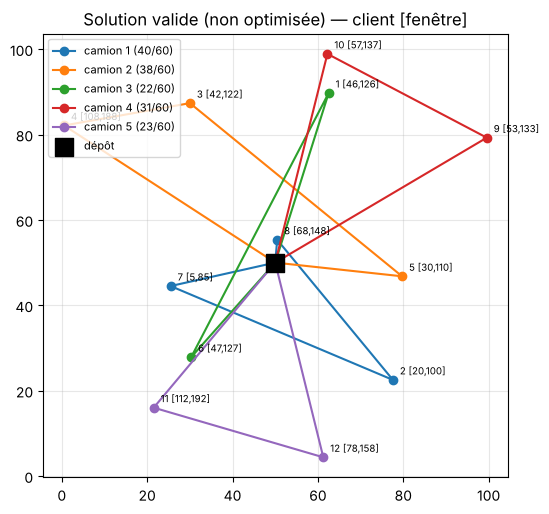

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
for k, route in enumerate(solution):
    xy = coords[[0] + route + [0]]
    ax.plot(xy[:, 0], xy[:, 1], "-o", label=f"camion {k + 1} ({q[route].sum()}/{Q})")
ax.scatter(*coords[0], marker="s", s=150, c="black", zorder=5, label="dépôt")
for c in range(1, n + 1):
    ax.annotate(f"{c} [{a[c]:.0f},{b[c]:.0f}]", coords[c], xytext=(5, 4),
                textcoords="offset points", fontsize=7)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Solution valide (non optimisée) — client [fenêtre]")
plt.show()

In [5]:
# Taille du PLNE CVRPTW (sections 5 et 6)
print(f"{'n':>6} | {'variables binaires':>18} | {'contraintes':>12}")
for n_ in (10, 50, 100, 1000, 5000):
    binaires = n_ * (n_ + 1)
    contraintes = (2 * n_ + 2) + 2 * n_ * (n_ - 1) + 2 * n_
    print(f"{n_:>6} | {binaires:>18,} | {contraintes:>12,}")

     n | variables binaires |  contraintes
    10 |                110 |          222
    50 |              2,550 |        5,102
   100 |             10,100 |       20,202
  1000 |          1,001,000 |    2,002,002
  5000 |         25,005,000 |   50,010,002


**Lecture.** La taille du modèle croît en $n^2$ : elle reste polynomiale et le modèle s'écrit sans problème. La vraie difficulté est le **nombre de combinaisons à explorer**, qui explose à cause de la NP-difficulté (section 4).

## 9. Synthèse

| Élément | Résultat |
|---|---|
| Problème | CVRPTW (niveau A), construit sur le CVRP (niveau B) |
| Objectif | minimiser la somme des temps de trajet |
| Complexité | NP-difficile (TSP → CVRP → CVRPTW) ; avec fenêtres, même trouver une solution valide est NP-complet |
| PLNE | variables $x_{ij}$ à 2 indices, MTZ pour la capacité et les sous-tours, $T_i$ et big-M ajustés pour les fenêtres |
| Trafic | vitesses par tranche horaire (FIFO), hors PLNE |

**Points à valider avec le tuteur :**
1. Graphe complet des plus courts chemins (H1) et durées fixes dans le PLNE (H5).
2. Objectif : temps de trajet plutôt que durée totale avec attente.
3. Trafic intégré au calcul des heures d'arrivée plutôt que dans le PLNE.

## 10. Références

1. Dantzig, G. B., & Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80–91.
2. Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326–329.
3. Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, 85–103. Springer.
4. Garey, M. R., & Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W. H. Freeman.
5. Lenstra, J. K., & Rinnooy Kan, A. H. G. (1981). Complexity of vehicle routing and scheduling problems. *Networks*, 11(2), 221–227.
6. Laporte, G., & Nobert, Y. (1983). A branch and bound algorithm for the capacitated vehicle routing problem. *OR Spektrum*, 5(2), 77–85.
7. Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4(1), 285–305.
8. Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265.
9. Ichoua, S., Gendreau, M., & Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379–396.
10. Toth, P., & Vigo, D. (Eds.) (2014). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM.